# Conlang Translator
<a id="title"></a>

[Project Repo](https://github.com/Ethereal-Mining-Company/conlang-translator) \
Christopher Doupis \
December 6, 2026

<div class="alert alert-info" style="color: black;">
    
### AI USE DISCLAIMER & ACADEMIC INTEGRITY COMPLIANCE
In compliance with the [**National University Student Guidelines for Generative AI**](https://resources.nu.edu/ai/ai-guidelines), this project discloses the following tool usage:

* **Conceptual Framing & Brainstorming (AI-Informed):** **Google Gemini** was utilized as a supplemental learning resource to clarify core mathematical and analytical concepts across the assignment questions. 
* **Technical Execution & Boilerplate Generation (AI-Assisted):** **Google Gemini** was used to generate initial code structures and programming boilerplates. These templates were subsequently modified, debugged, and tailored to meet the specific requirements of each question.
* **Human Oversight, Validation Loops & Refinement (Author-Owned):** The author maintained complete conceptual control, process oversight, and ownership of the entire homework scope. All AI-assisted templates, code logic, and conceptual outputs were systematically reviewed and validated by the author to ensure academic accuracy and integrity.
* **Disclosure Statement (AI-Generated):** **Google Gemini** was utilized to structure and audit this text format to fulfill all institutional reporting standards.
</div>

### REFERENCES
#### Peer Reviewed and Scientific References

#### Generative AI & Software Tools
* **[Google.](https://google.com)** (2026). *Gemini* [Large language model]. https://google.com

In [3]:
import json
from collections import Counter
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

from src.engine import DynamicTranslator
from src.features import load_dataset_splits
from src.models import diagnose_all_models, get_tagger, run_experiments
from src.utils import export_comparison_png, export_eda_png, export_epochs_png, load_config, resolve_path

cfg = load_config()
translator = DynamicTranslator(cfg["paths"]["languages_dir"], cfg["paths"]["english_rules"])

print("Active Languages:", translator.available_languages())
print("Default Production Model:", cfg["translator"]["active_model"])

Active Languages: ['english', 'aelorian', 'low_nerakan', 'vaelorian']
Default Production Model: random_forest


,Split,Sentences,Tokens
0,Train,12544,204578
1,Dev (Validation),2001,25148
2,Test (Held-Out),2077,25094


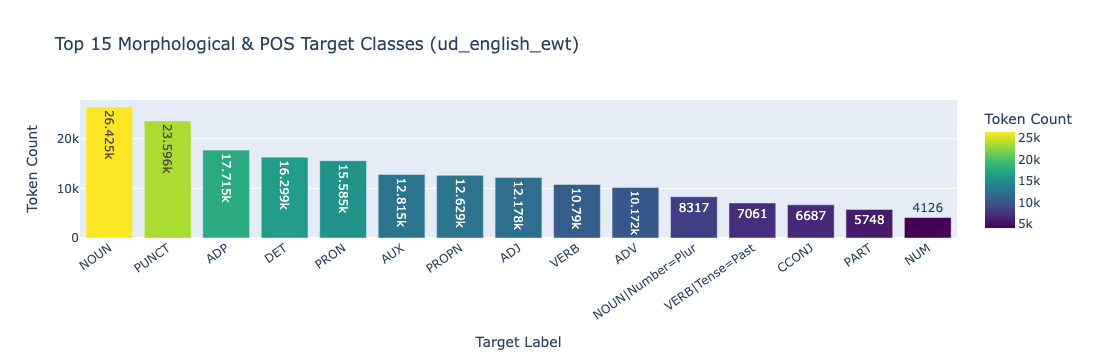

In [2]:
train_s, dev_s, test_s, source_tag = load_dataset_splits(cfg)

eda_df = pd.DataFrame([
    {"Split": "Train", "Sentences": len(train_s), "Tokens": sum(len(s) for s in train_s)},
    {"Split": "Dev (Validation)", "Sentences": len(dev_s), "Tokens": sum(len(s) for s in dev_s)},
    {"Split": "Test (Held-Out)", "Sentences": len(test_s), "Tokens": sum(len(s) for s in test_s)},
])
display(eda_df)

tag_counts = Counter(tok["label"] for sent in train_s for tok in sent)
top_tags_df = pd.DataFrame(tag_counts.most_common(15), columns=["Target Label", "Token Count"])

title_eda = f"Top 15 Morphological & POS Target Classes ({source_tag})"
export_eda_png(top_tags_df, "Target Label", "Token Count", title_eda, cfg["paths"]["figures"])

fig_eda = px.bar(
    top_tags_df,
    x="Target Label",
    y="Token Count",
    title=title_eda,
    text_auto=True,
    color="Token Count",
    color_continuous_scale="Viridis",
)
fig_eda.update_layout(xaxis_tickangle=-35, showlegend=False)
fig_eda.show()

In [18]:
import importlib
import src.models
import src.models.hist_gbdt
import src.models.mlp_tagger

importlib.reload(src.models.hist_gbdt)
importlib.reload(src.models.mlp_tagger)
importlib.reload(src.models)

src.models.run_experiments(
    models=["mlp_tagger", "hist_gbdt"],
    run_names={
        "hist_gbdt": ["HGB_Hashed2048", "HGB_MaxSafe4096"],
    },
    save_artifacts=True,
    force_overwrite=True,
)


--- Starting MLP_Compact [run_cdb1a9e8] ---
Iteration 1, loss = 0.37084025
Validation score: 0.952341
Iteration 2, loss = 0.08151956
Validation score: 0.953661
Iteration 3, loss = 0.04489981
Validation score: 0.954688
Iteration 4, loss = 0.03063688
Validation score: 0.955519
Iteration 5, loss = 0.02324848
Validation score: 0.955079
Iteration 6, loss = 0.01903081
Validation score: 0.956252
Iteration 7, loss = 0.01692014
Validation score: 0.955323
Iteration 8, loss = 0.01677449
Validation score: 0.953954
Iteration 9, loss = 0.01608444
Validation score: 0.953417
Validation score did not improve more than tol=0.000100 for 2 consecutive epochs. Stopping.


2026-11-17 00:47:39,150 | INFO | [run_cdb1a9e8] MLP_Compact | folds=1 | val_acc=0.9380 | time=411.87s



--- Starting MLP_Tuned [run_ef15bd5d] ---
Iteration 1, loss = 0.35198089
Validation score: 0.947013
Iteration 2, loss = 0.06898416
Validation score: 0.950435
Iteration 3, loss = 0.03271715
Validation score: 0.950044
Iteration 4, loss = 0.02003109
Validation score: 0.951999
Iteration 5, loss = 0.01229767
Validation score: 0.950337
Iteration 6, loss = 0.00974901
Validation score: 0.952439
Iteration 7, loss = 0.00861688
Validation score: 0.950875
Iteration 8, loss = 0.00793374
Validation score: 0.949409
Iteration 9, loss = 0.00816738
Validation score: 0.950582
Validation score did not improve more than tol=0.000100 for 2 consecutive epochs. Stopping.


2026-11-17 01:06:24,429 | INFO | [run_ef15bd5d] MLP_Tuned | folds=1 | val_acc=0.9362 | time=1125.27s
2026-11-17 01:06:25,011 | INFO | [run_cdb1a9e8] Promoted new champion (0.9380 > -1.0000)


HGB_Hashed2048 [run_7da8f812] [████████████████████] 100% | iter=200/200 | val_acc=0.9346 | ram=7.9GB

2026-11-17 01:36:20,207 | INFO | [run_7da8f812] HGB_Hashed2048 | folds=1 | val_acc=0.9346 | time=1794.32s



HGB_MaxSafe4096 [run_5bdf7923] [████████████████████] 100% | iter=300/300 | val_acc=0.9375 | ram=8.8GB

2026-11-17 02:56:23,045 | INFO | [run_5bdf7923] HGB_MaxSafe4096 | folds=1 | val_acc=0.9375 | time=4802.81s


2026-11-17 02:57:18,639 | INFO | [run_5bdf7923] Promoted new champion (0.9375 > -1.0000)


{'Random Forest': {'display_name': 'Random Forest',
  'best_run_uuid': 'run_b252c355',
  'best_run_name': 'RF_Tuned',
  'best_val_accuracy': 0.9263162080483538,
  'promoted': True,
  'sweep': [{'run_uuid': 'run_734836a2',
    'name': 'RF_Baseline',
    'tuned_params': {'n_estimators': 100,
     'max_depth': 30,
     'max_features': 'sqrt'},
    'val_accuracy': 0.701725783362494,
    'fold_scores': [0.701725783362494],
    'time_s': 3.11,
    'all_params': {'bootstrap': 'True',
     'ccp_alpha': '0.0',
     'class_weight': 'None',
     'criterion': 'gini',
     'max_depth': '30',
     'max_features': 'sqrt',
     'max_leaf_nodes': 'None',
     'max_samples': 'None',
     'min_impurity_decrease': '0.0',
     'min_samples_leaf': '1',
     'min_samples_split': '2',
     'min_weight_fraction_leaf': '0.0',
     'monotonic_cst': 'None',
     'n_estimators': '100',
     'n_jobs': '-1',
     'oob_score': 'False',
     'random_state': '42',
     'verbose': '0',
     'warm_start': 'False'}},
   {

=== ALL LOGGED EXPERIMENT RUNS ===


,run_uuid,engine_type,run_name,promoted,tuned_params,mean_cv_accuracy,final_test_score,macro_f1,latency_ms
0,run_780dfdd1,random_forest,RF_Run_1,False,"{'n_estimators': 50, 'max_depth': 20}",0.616510,NaN,NaN,NaN
1,run_e3b46cd3,random_forest,RF_Run_2,False,"{'n_estimators': 50, 'max_depth': 40}",0.783005,NaN,NaN,NaN
2,run_178dcd7b,random_forest,RF_Run_3,False,"{'n_estimators': 50, 'max_depth': None}",0.928662,NaN,NaN,NaN
3,run_5b1b2291,random_forest,RF_Run_4,False,"{'n_estimators': 200, 'max_depth': 20}",0.622634,NaN,NaN,NaN
4,run_963228ec,random_forest,RF_Run_5,False,"{'n_estimators': 200, 'max_depth': 40}",0.789606,NaN,NaN,NaN
5,run_23bc0b84,random_forest,RF_Run_6,True,"{'n_estimators': 200, 'max_depth': None}",0.930491,0.929266,0.870476,0.1579
6,run_2db728ef,random_forest,RF_Run_1,False,"{'n_estimators': 50, 'max_depth': 20}",0.616510,NaN,NaN,NaN
7,run_3ea8af9b,random_forest,RF_Run_2,False,"{'n_estimators': 50, 'max_depth': 40}",0.783005,NaN,NaN,NaN
8,run_2844d6d3,random_forest,RF_Run_3,False,"{'n_estimators': 50, 'max_depth': None}",0.928662,NaN,NaN,NaN
9,run_9adb7005,random_forest,RF_Run_4,False,"{'n_estimators': 200, 'max_depth': 20}",0.622634,NaN,NaN,NaN


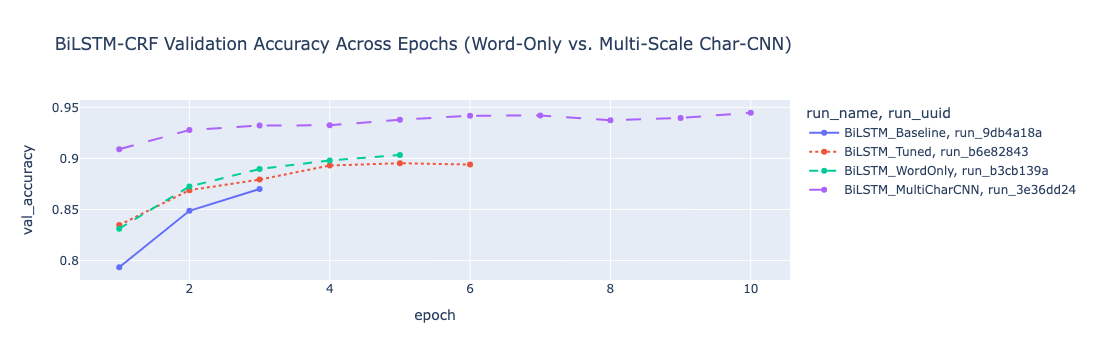

In [19]:
runs_df = pd.read_csv(resolve_path(cfg["paths"]["runs_csv"]))
epochs_df = pd.read_csv(resolve_path(cfg["paths"]["epochs_csv"]))

print("=== ALL LOGGED EXPERIMENT RUNS ===")
display(runs_df[["run_uuid", "engine_type", "run_name", "promoted", "tuned_params", "mean_cv_accuracy", "final_test_score", "macro_f1", "latency_ms"]])

bilstm_epochs = epochs_df[epochs_df["engine_type"] == "bilstm_crf"]
if not bilstm_epochs.empty:
    title_ep = "BiLSTM-CRF Validation Accuracy Across Epochs (Word-Only vs. Multi-Scale Char-CNN)"
    export_epochs_png(bilstm_epochs, title_ep, cfg["paths"]["figures"])
    fig_ep = px.line(
        bilstm_epochs,
        x="epoch",
        y="val_accuracy",
        color="run_name",
        line_dash="run_uuid",
        markers=True,
        title=title_ep,
    )
    fig_ep.show()

,Model,Champion Run,Run UUID,Test Accuracy,Macro F1,Latency (ms/sent)
0,Random Forest,RF_Tuned,run_b252c355,0.925998,0.861088,0.598994
1,BiLSTM-CRF,BiLSTM_MultiCharCNN,run_3e36dd24,0.949071,0.908096,1.301744
2,HistGradientBoosting,HGB_MaxSafe4096,run_5bdf7923,0.939428,0.893828,26.303586
3,MLP Neural Net,MLP_Compact,run_cdb1a9e8,0.940384,0.890322,0.091387


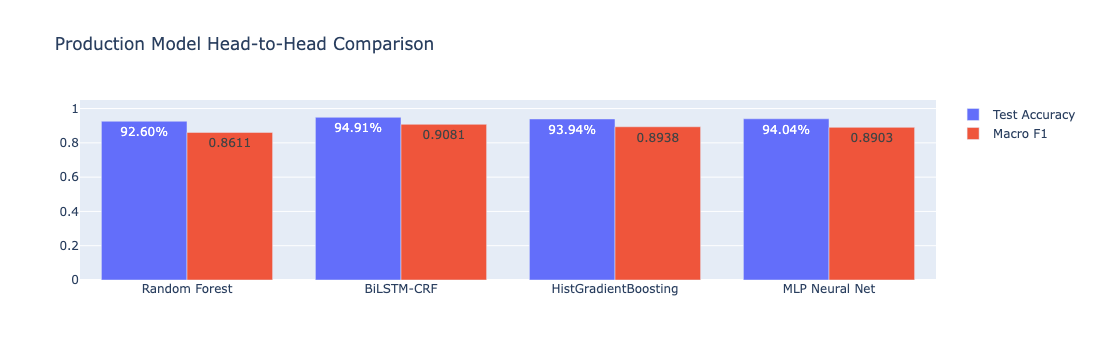

In [20]:
metrics_path = resolve_path(cfg["paths"]["artifacts_prod"]) / cfg["runtime"]["metrics_file"]
metrics_data = json.loads(metrics_path.read_text(encoding="utf-8"))

comp_rows = [
    {
        "Model": family,
        "Champion Run": info["best_run_name"],
        "Run UUID": info["best_run_uuid"],
        "Test Accuracy": info["best_test_metrics"]["test_accuracy"],
        "Macro F1": info["best_test_metrics"]["macro_f1"],
        "Latency (ms/sent)": info["best_test_metrics"]["latency_ms"],
    }
    for family, info in metrics_data.items()
]
comp_df = pd.DataFrame(comp_rows)
display(comp_df)

title_comp = "Production Model Head-to-Head Comparison"
export_comparison_png(comp_df, title_comp, cfg["paths"]["figures"])

fig_comp = go.Figure(data=[
    go.Bar(name="Test Accuracy", x=comp_df["Model"], y=comp_df["Test Accuracy"], text=comp_df["Test Accuracy"].map(lambda v: f"{v:.2%}"), textposition="auto"),
    go.Bar(name="Macro F1", x=comp_df["Model"], y=comp_df["Macro F1"], text=comp_df["Macro F1"].map(lambda v: f"{v:.4f}"), textposition="auto"),
])
fig_comp.update_layout(barmode="group", title=title_comp, yaxis_range=[0, 1.05])
fig_comp.show()

In [2]:
import importlib
import src.models
import src.models.hist_gbdt
import src.models.mlp_tagger

importlib.reload(src.models.hist_gbdt)
importlib.reload(src.models.mlp_tagger)
importlib.reload(src.models)

tagger, model_name = get_tagger(cfg)
print(f"Active Production Tagger: {model_name}\n")

test_sentences = [
    "The nine spires bind the life of Ur.",
    "Three wizards ran into Waterdeep.",
    "When the Crimson Wyrm awakens, only he who bears the Dawnblade may sever the weave.",
    "STOP DANGER",
]

for sent in test_sentences:
    ae_out = translator.translate(sent, "english", "aelorian", tagger)
    en_back = translator.translate(ae_out, "aelorian", "english", tagger)
    print(f"EN  : {sent}")
    print(f"AE  : {ae_out}")
    print(f"BACK: {en_back}\n")

diag_sentence = "I love Madison and she can cast fireball."
diag_res = diagnose_all_models(diag_sentence, cfg)
diag_rows = list()
first_key = next(iter(diag_res))
base_tokens = diag_res[first_key]["tokens"]

for idx, tok in enumerate(base_tokens):
    row = {"Token": tok["word"]}
    for k, info in diag_res.items():
        row[info["display_name"]] = info["tokens"][idx]["label"]
    labels = [row[info["display_name"]] for info in diag_res.values()]
    row["Agreement"] = "AGREE" if len(set(labels)) == 1 else "DIFF"
    diag_rows.append(row)

print(f"=== MULTI-MODEL DIAGNOSTICS: '{diag_sentence}' ===")
display(pd.DataFrame(diag_rows))

NameError: name 'get_tagger' is not defined

Top-level keys: ['name', 'code', 'word_order', 'adjective_position', 'determiner_position', 'adposition_type', 'affixes']
Affixes: {'PLUR': {'type': 'suffix', 'form': 'as'}, 'PAST': {'type': 'suffix', 'form': 'en'}, 'FUT': {'type': 'suffix', 'form': 'ir'}, 'COMP': {'type': 'suffix', 'form': 'iel'}, 'SUPER': {'type': 'suffix', 'form': 'ish'}}
Proper nouns count: 0
Multiword count: 0

Sample lookups:
  NOUN['wizard'] -> None
  VERB['run']    -> None
  ADP['to']      -> None
  DET['the']     -> None
  PROPN['Waterdeep'] -> None
